# Buổi C1: Hồi quy logistic, từ đường thẳng đến đường cong chữ S

**Hiện trường.** Chị Mai chủ vườn ươm nhận một lô 100 cây giống thuộc hai loại hoa **iris versicolor** và **iris virginica**, nhưng nhãn mác bị ướt mưa nhòe hết. Hai loại này bán giá khác nhau nên phải tách. Chị chỉ có cây thước: đo được **bề rộng cánh hoa** (và chiều dài cánh hoa) của từng cây. Chị hỏi: *"Chỉ nhìn bề rộng cánh hoa, tôi đoán loại nào được không, và chắc chắn đến đâu?"*

Ở A6 ta đã dùng `LogisticRegression` như một hộp đen. Hôm nay ta **mở hộp ra**.

**Câu hỏi của buổi này:** *làm sao biến một đường thẳng thành cỗ máy đoán "loại nào" và nói được "chắc chắn bao nhiêu phần trăm"?*

**Mindset của người làm dữ liệu:** với bài phân loại, câu trả lời hữu ích không phải "loại A" mà là "loại A, chắc khoảng 90%". Mô hình biết nói **mức chắc chắn** mới đáng tin hơn mô hình chỉ phán xuôi.

**Lưu ý:** dữ liệu iris là dữ liệu mẫu để học. Buổi này dùng lại cú pháp từ A1 đến B7 và hộp đồ nghề của A6; chỉ giải thích điều **mới**.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Vì sao đường thẳng của hồi quy không đủ cho bài đoán nhóm |
| Chặng 2 | Hàm sigmoid: ép đường thẳng vào khoảng từ 0 đến 1 |
| Chặng 3 | Đọc `intercept_` và `coef_`: log-odds, odds và điểm 50/50 |
| Chặng 4 | `fit` làm gì: chấm điểm bằng log-loss, phạt nặng kẻ tự tin mà sai |
| Chặng 5 | Nhiều cột, đường biên quyết định và núm vặn `C` |
| Chặng 6 | Kiểm định và giới hạn: khi ranh giới không phải đường thẳng |

## Chặng 1: Vì sao đường thẳng của hồi quy không đủ cho bài đoán nhóm

**Câu hỏi:** ta vừa học hồi quy tuyến tính (B1 đến B6). Cứ mã hóa virginica là **1**, versicolor là **0**, rồi cho `LinearRegression` đoán số, được không?

Thử ngay, rồi xem nó hỏng ở đâu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
iris = load_iris(as_frame=True).frame
iris = iris[iris["target"] > 0].copy()
iris["is_virginica"] = (iris["target"] == 2).astype(int)
iris.columns = [c.replace(" (cm)", "").replace(" ", "_") for c in iris.columns]
X = iris[["petal_width"]]
y = iris["is_virginica"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(X_train.shape, X_test.shape, y_train.value_counts().to_dict())
iris[["petal_length", "petal_width", "is_virginica"]].head(3)

(75, 1) (25, 1) {1: 38, 0: 37}


,petal_length,petal_width,is_virginica
50,4.7,1.4,0
51,4.5,1.5,0
52,4.9,1.5,0


**Giải thích từng dòng**

- `from sklearn.datasets import load_iris`: (đã học) lấy bộ dữ liệu hoa iris.
- `iris = iris[iris["target"] > 0].copy()`: (đã học lọc dòng ở A2) iris có ba loài mã 0, 1, 2. Ta bỏ loài 0 (setosa, quá dễ tách) và giữ hai loài **1 (versicolor) và 2 (virginica)**: còn 100 cây. `.copy()` tạo bản sao để sửa thoải mái mà không đụng bảng gốc.
- `iris["is_virginica"] = (iris["target"] == 2).astype(int)`: (đã học `astype` ở A2) tạo cột đáp án mới: **1** nếu là virginica, **0** nếu là versicolor. Phép so sánh cho Đúng/Sai, `.astype(int)` đổi thành 1/0.
- `iris.columns = [c.replace(" (cm)", "").replace(" ", "_") for c in iris.columns]`: đổi tên cột cho gọn: bỏ chữ "(cm)" và thay khoảng trắng bằng dấu gạch dưới (`petal width (cm)` thành `petal_width`). Phép lặp trong ngoặc vuông đã học ở B4; `.replace(a, b)` của chuỗi là thay chữ `a` bằng chữ `b`.
- `X = iris[["petal_width"]]`: (đã học ở B1) hai lớp ngoặc vuông cho ra **bảng một cột**, đúng hình dạng sklearn cần cho `X`.
- `train_test_split(..., test_size=0.25, random_state=42, stratify=y)`: (đã học) chia 75/25, giữ tỉ lệ hai loài đều nhau ở cả hai phần (`stratify`, đã học ở A6): 75 cây học, 25 cây thi, loài nào cũng khoảng một nửa.

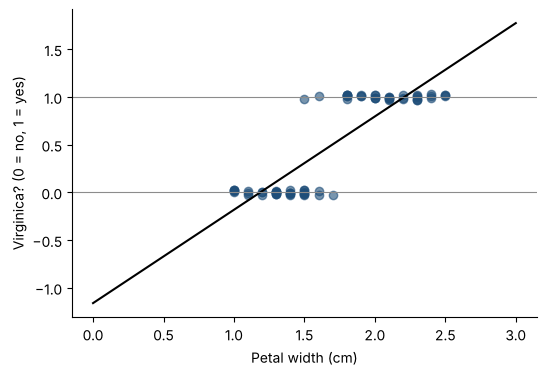

 petal_width  linear prediction
         0.5              -0.67
         1.0              -0.18
         2.5               1.29
         3.0               1.77


In [3]:
line = LinearRegression().fit(X_train, y_train)
grid = pd.DataFrame({"petal_width": np.linspace(0, 3, 100)})
plt.scatter(X_train["petal_width"], y_train + np.random.default_rng(0).uniform(-0.03, 0.03, len(y_train)), color=BLUE, alpha=0.6)
plt.plot(grid["petal_width"], line.predict(grid), color="black")
plt.axhline(0, color=GRAY, linewidth=0.8); plt.axhline(1, color=GRAY, linewidth=0.8)
plt.xlabel("Petal width (cm)"); plt.ylabel("Virginica? (0 = no, 1 = yes)")
plt.show()
print(pd.DataFrame({"petal_width": [0.5, 1.0, 2.5, 3.0], "linear prediction": line.predict(pd.DataFrame({"petal_width": [0.5, 1.0, 2.5, 3.0]})).round(2)}).to_string(index=False))

**Giải thích từng dòng**

- `line = LinearRegression().fit(X_train, y_train)`: (đã học ở B1) vẫn là hồi quy tuyến tính, chỉ khác `y` toàn là 0 và 1.
- `grid = pd.DataFrame({"petal_width": np.linspace(0, 3, 100)})`: 100 giá trị bề rộng cánh hoa trải đều từ 0 đến 3 cm, để vẽ đường. Bọc vào bảng một cột tên `petal_width` để khớp tên cột lúc học (sklearn đối chiếu tên cột).
- `y_train + np.random.default_rng(0).uniform(-0.03, 0.03, len(y_train))`: các điểm đều nằm đúng hàng 0 hoặc 1 nên chồng khít lên nhau; ta cộng **một chút nhiễu ngẫu nhiên** (từ −0,03 đến +0,03) chỉ để nhìn thấy từng điểm. Chỉ ảnh hưởng hình vẽ, không ảnh hưởng mô hình. `default_rng(0)` là bộ số ngẫu nhiên có hạt giống 0.
- `plt.axhline(0, ...); plt.axhline(1, ...)`: (đã học) hai đường ngang xám đánh dấu hai mức 0 và 1: ranh giới của một xác suất hợp lệ.
- `line.predict(pd.DataFrame(...))`: hỏi đường thẳng sẽ "đoán" bao nhiêu cho bốn cây có bề rộng cánh 0,5; 1,0; 2,5 và 3,0 cm.

**Cách đọc**

- **Con số:** cây có cánh rộng 0,5 cm bị đường thẳng đoán **-0,67** (âm!), còn cây cánh rộng 3 cm bị đoán **1,77** (vượt 1!).
- **Bức tranh:** các điểm xanh chia thành hai đám, một đám ở hàng 0 (versicolor, cánh hẹp) và một đám ở hàng 1 (virginica, cánh rộng). Đường đen đi chéo qua giữa, nhưng nó **không chịu dừng** ở mức 0 và 1 mà chui xuống dưới 0 bên trái, vọt lên trên 1 bên phải.
- **Ý nghĩa:** nếu ta hiểu con số là "khả năng là virginica" thì **một con số âm hay một con số lớn hơn 1 đều vô nghĩa**: khả năng không thể âm, cũng không thể hơn 100%. Hơn nữa đường thẳng cố gắng *sát từng điểm* nên vài cây cánh rất rộng cũng kéo cả đường nghiêng đi, dù chúng đã quá chắc chắn.

Ta cần một đường **đi từ 0 lên 1 rồi dừng**, hình chữ S. Đó là ý tưởng của hồi quy logistic.

**Mang về chặng 1:** đoán nhóm bằng đường thẳng cho kết quả ngoài khoảng 0 đến 1, vô nghĩa nếu hiểu là xác suất. Cần một đường cong bị "chặn" ở hai đầu.

## Chặng 2: Hàm sigmoid, ép đường thẳng vào khoảng từ 0 đến 1

**Câu hỏi:** có phép biến đổi nào nhận *mọi số thực* (kể cả −7 hay +40) và trả ra *một số từ 0 đến 1*?

Có, gọi là **hàm sigmoid** (hình chữ S):

**p = 1 / (1 + e^(−z))**

Trong đó `e` là hằng số 2,718... và `z` là **kết quả của đường thẳng**: `z = intercept + coef × x`. Hồi quy logistic làm hai bước: (1) tính đường thẳng `z` như B1, (2) cho `z` đi qua sigmoid để ra xác suất `p`.

Xem hình dáng hàm sigmoid trước khi gắn vào dữ liệu:

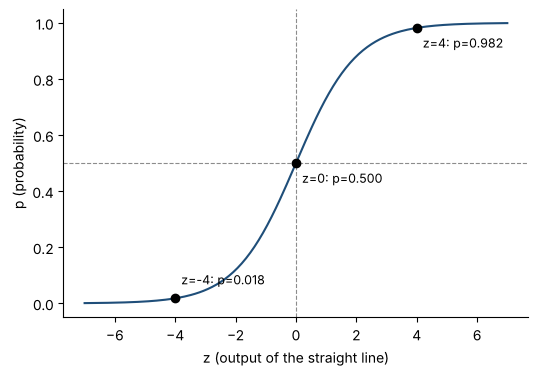

In [4]:
z = np.linspace(-7, 7, 200)
p = 1 / (1 + np.exp(-z))
plt.plot(z, p, color=BLUE)
plt.axhline(0.5, color=GRAY, linestyle="--", linewidth=0.8); plt.axvline(0, color=GRAY, linestyle="--", linewidth=0.8)
for zz in [-4, 0, 4]:
    plt.plot(zz, 1 / (1 + np.exp(-zz)), "o", color="black")
    plt.text(zz + 0.2, 1 / (1 + np.exp(-zz)) + (0.05 if zz < 0 else -0.07), f"z={zz}: p={1 / (1 + np.exp(-zz)):.3f}", fontsize=9)
plt.xlabel("z (output of the straight line)"); plt.ylabel("p (probability)")
plt.show()

**Giải thích từng dòng**

- `z = np.linspace(-7, 7, 200)`: (đã học) 200 giá trị `z` từ −7 đến 7: ta giả sử đường thẳng đã cho ra những giá trị đó.
- `p = 1 / (1 + np.exp(-z))`: **mới:** công thức sigmoid. `np.exp(x)` tính e mũ x, áp dụng cho cả dãy `z` một lượt. Mẹo đọc: `z` rất lớn thì `exp(-z)` gần 0 nên `p` gần 1; `z` rất âm thì `exp(-z)` rất lớn nên `p` gần 0; `z = 0` thì `exp(0) = 1` nên `p = 1/2`.
- `plt.axhline(0.5, ...); plt.axvline(0, ...)`: đường kẻ đứt đánh dấu điểm giữa: `z = 0` ứng với `p = 0,5`.
- `for zz in [-4, 0, 4]: ... plt.text(...)`: (đã học vòng lặp và `plt.text`) chấm ba điểm tiêu biểu và ghi giá trị `p` bên cạnh. Chữ `f"...:.3f"` là f-string làm tròn ba chữ số lẻ.

**Cách đọc**

- **Con số:** `z = 0` cho `p = 0,500`; `z = 4` cho `p = 0,982`; `z = −4` cho `p = 0,018`.
- **Bức tranh:** đường sigmoid là chữ S nằm ngang: **ở giữa dốc** (đổi `z` một chút là `p` đổi nhiều) và **hai đầu phẳng dần** (từ `z = 4` trở đi, tăng thêm bao nhiêu thì `p` cũng chỉ nhích sát 1). Nó không bao giờ chạm đúng 0 hay đúng 1.
- **Ý nghĩa:** sigmoid biến "độ lệch về phía virginica" thành **mức chắc chắn**: lệch ít thì chưa chắc, lệch nhiều thì rất chắc, nhưng không bao giờ "chắc 100%".

Giờ ghép với dữ liệu hoa. **Hồ sơ của mô hình** (để ta nhớ nó cần gì):

| Mục | `LogisticRegression` |
|---|---|
| **Nó là gì** | Đường thẳng `z` + sigmoid, cho ra **xác suất** thuộc mỗi nhóm |
| **Dùng khi nào** | Đoán **nhóm** (có/không, loại A/B/C), muốn biết cả mức chắc chắn; ranh giới giữa nhóm gần như phẳng |
| **`X`** | Bảng **toàn số**, hình (n dòng, k cột). Cột chữ phải đổi thành số trước (one-hot, B4). Nên chuẩn hóa khi có nhiều cột (chặng 5) |
| **`y`** | Một cột **nhãn** (số 0/1, hoặc chữ như "ác"/"lành"), **không** phải số đo liên tục |
| **Ô trống `NaN` trong `X`** | **Không chịu**: báo lỗi. Phải điền hoặc bỏ trước (`SimpleImputer`, B4) |
| **Module sklearn** | `sklearn.linear_model.LogisticRegression` |
| **`fit` / `predict`** | `fit(X, y)` học `coef_`, `intercept_`; `predict(X)` trả **nhãn**; `predict_proba(X)` trả **xác suất** |
| **Sau `fit` có gì** | `intercept_`, `coef_`, `classes_` (thứ tự các nhóm) |

classes_  : [0 1]
intercept_: [-6.627] | shape: (1,)
coef_     : [[3.945]] | shape: (1, 1)


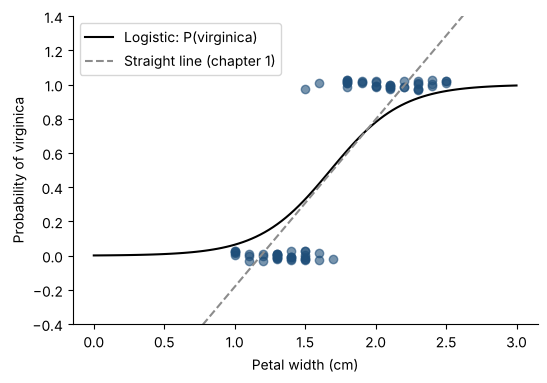

In [5]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression().fit(X_train, y_train)
print("classes_  :", model.classes_)
print("intercept_:", model.intercept_.round(3), "| shape:", model.intercept_.shape)
print("coef_     :", model.coef_.round(3), "| shape:", model.coef_.shape)
plt.scatter(X_train["petal_width"], y_train + np.random.default_rng(0).uniform(-0.03, 0.03, len(y_train)), color=BLUE, alpha=0.6)
plt.plot(grid["petal_width"], model.predict_proba(grid)[:, 1], color="black", label="Logistic: P(virginica)")
plt.plot(grid["petal_width"], line.predict(grid), color=GRAY, linestyle="--", label="Straight line (chapter 1)")
plt.ylim(-0.4, 1.4); plt.legend(loc="upper left")
plt.xlabel("Petal width (cm)"); plt.ylabel("Probability of virginica")
plt.show()

**Giải thích từng dòng**

- `from sklearn.linear_model import LogisticRegression`: (đã gặp ở A6) lấy máy hồi quy logistic.
- `model = LogisticRegression().fit(X_train, y_train)`: tạo máy với cài đặt mặc định rồi học. Từ giờ ta gọi tên `model` cho mô hình đã học.
- `model.classes_`: danh sách các nhóm theo **thứ tự máy dùng**: `[0 1]`. Cột đầu của `predict_proba` ứng với `0`, cột sau ứng với `1`.
- `model.intercept_.round(3)`: `intercept_` (đã học ở B1) nhưng ở đây là **một mảng một phần tử**, không phải một số lẻ: sklearn dùng chung cách lưu cho bài nhiều nhóm.
- `model.coef_.round(3)`: `coef_` có hình **(1, 1)**: *một dòng* (một bài toán nhị phân) và *một cột* (một cột đề). Với `k` cột đề sẽ là (1, k).
- `model.predict_proba(grid)[:, 1]`: (đã học ở A6) cột số 1 là xác suất của nhóm `1` (virginica) tại từng bề rộng trong `grid`.

**Cách đọc**

- **Con số:** `intercept_` = **-6,63**, `coef_` = **3,94**. Nghĩa là `z = -6,63 + 3,94 × bề rộng`.
- **Bức tranh:** đường đen hình chữ S bắt đầu sát 0 ở bên trái (cánh hẹp: gần như chắc chắn versicolor), leo dốc **quanh 1,7 cm**, rồi sát 1 bên phải. Đường xám đứt (đường thẳng của chặng 1) vẫn chui ra ngoài khoảng 0 đến 1. Hai đường đi qua cùng đám điểm nhưng chỉ đường chữ S là *đọc được như xác suất*.
- **Ý nghĩa:** với cánh hẹp hơn 1,0 cm máy chắc trên 93% là versicolor; với cánh rộng hơn 2,3 cm máy chắc trên 90% là virginica. Cái đáng bàn là **đoạn dốc ở giữa**, nơi hai loài chồng lên nhau, và máy nói *"không chắc"* bằng con số giữa 0 và 1.

**Mang về chặng 2:** hồi quy logistic = đường thẳng `z = intercept + coef × x` rồi qua **sigmoid** để thành xác suất. `LogisticRegression` cần `X` toàn số, không `NaN`; `y` là nhãn.

## Chặng 3: Đọc `intercept_` và `coef_`, log-odds, odds và điểm 50/50

**Câu hỏi:** hai con số máy học được nói gì với chị Mai?

Chị Mai đọc `z` thì khó, nên ta dịch ba tầng:

- **Xác suất `p`**: "khả năng là virginica", từ 0 đến 1.
- **Odds** (tỉ lệ cược): `p / (1 − p)`. Nếu `p = 0,75` thì odds = 3: "cứ 3 lần là virginica thì 1 lần là versicolor".
- **Log-odds**: logarit tự nhiên của odds. *Chính `z` là log-odds.* Đây là lý do `coef_` là **"mỗi cm bề rộng thêm, log-odds tăng thêm bấy nhiêu"**.

Vì log-odds khó hình dung, ta lấy **e mũ coef** để về dạng odds: *mỗi cm bề rộng thêm, odds nhân lên bấy nhiêu lần*.

In [6]:
b0, b1 = model.intercept_[0], model.coef_[0][0]
odds_ratio = np.exp(b1)
midpoint = -b0 / b1
print(f"z = {b0:.2f} + {b1:.2f} * width")
print(f"each +1 cm of width multiplies the odds of virginica by exp({b1:.2f}) = {odds_ratio:.1f}")
print(f"each +0.1 cm multiplies the odds by exp({b1 * 0.1:.2f}) = {np.exp(b1 * 0.1):.2f}")
print(f"50/50 point (z = 0): width = -intercept / coef = {midpoint:.2f} cm")

z = -6.63 + 3.94 * width
each +1 cm of width multiplies the odds of virginica by exp(3.94) = 51.7
each +0.1 cm multiplies the odds by exp(0.39) = 1.48
50/50 point (z = 0): width = -intercept / coef = 1.68 cm


**Giải thích từng dòng**

- `b0, b1 = model.intercept_[0], model.coef_[0][0]`: lấy hai con số ra khỏi mảng: `[0]` là phần tử đầu của `intercept_`; `[0][0]` là *dòng 0, cột 0* của `coef_`. Gán cùng lúc cho hai biến.
- `odds_ratio = np.exp(b1)`: e mũ hệ số: **tỉ số odds** khi `x` tăng 1.
- `np.exp(b1 * 0.1)`: tăng 0,1 cm thì log-odds tăng `0,1 × b1`, nên odds nhân `exp(0,1 × b1)`: dễ hình dung hơn cho một bước nhỏ.
- `midpoint = -b0 / b1`: điểm `z = 0` (xác suất 50%): giải `b0 + b1 × x = 0` ra `x = −b0 / b1`.

**Cách đọc**

- **Con số:** mỗi cm bề rộng cánh tăng thêm, odds là virginica **nhân lên khoảng 52 lần**; mỗi **0,1 cm** thì nhân lên khoảng **1,48 lần**. Điểm 50/50 nằm ở bề rộng **1,68 cm**.
- **Bức tranh:** hãy tưởng tượng một chiếc ***cầu bập bênh*** đặt điểm tựa ở 1,68 cm. Cánh hẹp hơn mốc đó, bập bênh nghiêng về phía versicolor; rộng hơn, nghiêng về virginica. Hệ số lớn nghĩa là bập bênh **rất nhạy**: chênh thêm vài mm là đổi hẳn cán cân.
- **Ý nghĩa:** con số "nhân 52 lần mỗi cm" nghe lớn vì **cả khoảng biến thiên của bề rộng chỉ vài cm** (hai loài khác nhau khoảng 0,7 cm ở trung bình). Dùng bước **0,1 cm** để đọc cho thực tế.
- **Cẩn thận:** `coef_` tác động lên **log-odds**, không phải lên xác suất. Cùng một bước 0,1 cm, xác suất đổi *nhiều* ở giữa dốc và *rất ít* ở hai đầu.

Kiểm chứng bằng tay: tự tính xác suất cho một cây rồi so với `predict_proba`.

In [7]:
one = pd.DataFrame({"petal_width": [1.9]})
z_hand = b0 + b1 * 1.9
p_hand = 1 / (1 + np.exp(-z_hand))
print(f"by hand : z = {z_hand:.3f} -> p(virginica) = {p_hand:.4f}")
print(f"sklearn : p(virginica) = {model.predict_proba(one)[0, 1]:.4f}")
print(f"odds = {p_hand / (1 - p_hand):.2f}, log-odds = {np.log(p_hand / (1 - p_hand)):.3f} (equals z)")

by hand : z = 0.868 -> p(virginica) = 0.7044
sklearn : p(virginica) = 0.7044
odds = 2.38, log-odds = 0.868 (equals z)


**Giải thích từng dòng**

- `one = pd.DataFrame({"petal_width": [1.9]})`: một cây giả định có cánh rộng 1,9 cm.
- `z_hand = b0 + b1 * 1.9`: bước 1: đường thẳng cho `z`.
- `p_hand = 1 / (1 + np.exp(-z_hand))`: bước 2: sigmoid cho `p`.
- `model.predict_proba(one)[0, 1]`: kết quả của sklearn: dòng 0 (duy nhất), cột 1. `[0, 1]` là cách lấy một ô theo (dòng, cột).
- `np.log(p_hand / (1 - p_hand))`: `np.log` là logarit tự nhiên (ngược của `np.exp`): biến odds về log-odds, kiểm tra nó đúng bằng `z`.

**Cách đọc:** tay và sklearn ra **cùng một con số** (0,7044). Không có phép màu nào: `predict_proba` chỉ là hai bước ta vừa làm. Cây cánh rộng 1,9 cm có xác suất virginica khoảng **70%**, odds khoảng 2,4.

**Mang về chặng 3:** `coef_` là **log-odds mỗi đơn vị `x`**; `exp(coef_)` là **tỉ số odds mỗi đơn vị `x`**; điểm 50/50 là `−intercept_ / coef_`. Đọc theo bước nhỏ cho thực tế.

## Chặng 4: `fit` làm gì, chấm điểm bằng log-loss, phạt nặng kẻ tự tin mà sai

**Câu hỏi:** ở B1, `fit` chọn đường làm *tổng bình phương sai lệch* nhỏ nhất. Với xác suất thì "sai lệch" tính thế nào?

Giả sử cây thật là virginica (nhãn 1) và máy cho `p = xác suất virginica`. Máy bị **phạt** theo công thức đơn giản:

- Nếu cây thật là virginica: phạt **−log(p)**.
- Nếu cây thật là versicolor: phạt **−log(1 − p)**.

Gộp lại, trung bình mức phạt qua mọi cây gọi là **log-loss** (còn gọi cross-entropy). `fit` chọn `intercept_` và `coef_` làm log-loss nhỏ nhất, tương tự cái bát của B1. Hình dung hình phạt:

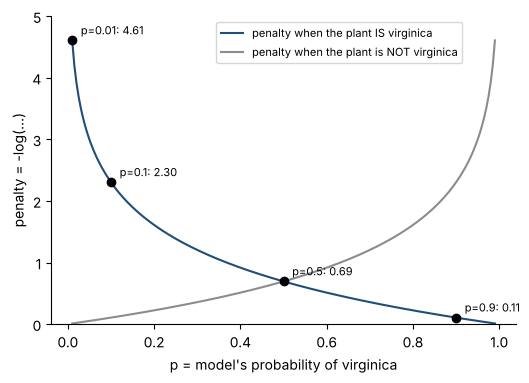

In [8]:
p = np.linspace(0.01, 0.99, 200)
plt.plot(p, -np.log(p), color=BLUE, label="penalty when the plant IS virginica")
plt.plot(p, -np.log(1 - p), color=GRAY, label="penalty when the plant is NOT virginica")
for pp in [0.9, 0.5, 0.1, 0.01]:
    plt.plot(pp, -np.log(pp), "o", color="black")
    plt.text(pp + 0.02, -np.log(pp) + 0.1, f"p={pp}: {-np.log(pp):.2f}", fontsize=8)
plt.ylim(0, 5); plt.xlabel("p = model's probability of virginica"); plt.ylabel("penalty = -log(...)")
plt.legend(loc="upper center", bbox_to_anchor=(0.62, 1.0), fontsize=8); plt.show()

**Giải thích từng dòng**

- `p = np.linspace(0.01, 0.99, 200)`: xác suất từ 0,01 đến 0,99 (tránh đúng 0 và 1 vì `log(0)` không xác định).
- `-np.log(p)`: hình phạt khi cây **thật sự là virginica** mà máy cho xác suất `p`: `p` càng nhỏ phạt càng nặng.
- `-np.log(1 - p)`: hình phạt khi cây **không phải** virginica: máy càng đòi `p` cao càng bị phạt nặng.
- `plt.ylim(0, 5)`: cắt trục dọc ở 5 vì phạt tiến tới vô cực khi `p` sát 0.

**Cách đọc**

- **Con số:** cây thật là virginica. Máy chắc 90% (`p = 0,9`) bị phạt chỉ **0,11**; chỉ nghiêng nhẹ 50/50 bị phạt **0,69**; máy chắc 90% là *versicolor* (`p = 0,1`) bị phạt **2,30**; chắc 99% là versicolor (`p = 0,01`) bị phạt **4,61**.
- **Bức tranh:** đường xanh **dốc đứng lên** khi `p` tiến về 0. Đoán sai mà **rất tự tin** là cái sai bị trừng phạt dữ dội nhất; đoán sai mà dè dặt thì chịu phạt nhẹ.
- **Ý nghĩa:** log-loss dạy máy **khiêm tốn khi chưa chắc**. Cũng vì thế *đúng nhãn chưa đủ*: hai mô hình cùng đúng 22/25 cây vẫn có log-loss khác nhau nếu một mô hình nói "chắc 99%" ở cây sai còn mô hình kia nói "chắc 60%".

Xem log-loss của mô hình thật, so với một mô hình "lười" luôn nói 50/50:

In [9]:
from sklearn.metrics import log_loss, accuracy_score
proba_test = model.predict_proba(X_test)
print("log-loss, our model      :", round(log_loss(y_test, proba_test), 3))
print("log-loss, always 50/50   :", round(log_loss(y_test, np.full(len(y_test), 0.5)), 3), "(= -log(0.5))")
print("accuracy, our model      :", round(accuracy_score(y_test, model.predict(X_test)), 2), f"({int((model.predict(X_test) == y_test).sum())} of {len(y_test)})")

log-loss, our model      : 0.409
log-loss, always 50/50   : 0.693 (= -log(0.5))
accuracy, our model      : 0.88 (22 of 25)


**Giải thích từng dòng**

- `from sklearn.metrics import log_loss, accuracy_score`: lấy hai thước đo: `log_loss` (như trên) và `accuracy_score` (tỉ lệ đoán đúng nhãn).
- `log_loss(y_test, proba_test)`: nhận đáp án thật và **bảng xác suất** (không phải nhãn): hàm tự lấy đúng cột cho từng cây.
- `np.full(len(y_test), 0.5)`: `np.full(n, v)` tạo mảng `n` phần tử cùng bằng `v`: ở đây máy lười luôn cho `p = 0,5`.
- `(model.predict(X_test) == y_test).sum()`: đếm số cây đoán đúng: phép `==` cho Đúng/Sai từng cây, `.sum()` cộng số Đúng.

**Cách đọc:** log-loss của mô hình là **0,409**, thấp hơn nhiều so với mức **0,693** của máy lười luôn nói 50/50 (mốc đáy tự nhiên: dưới nó là có học được gì đó). Độ đúng nhãn **88%** (22 trên 25 cây). Chú ý: tập thi chỉ có **25 cây**, một cây đoán sai đổi độ đúng 4 điểm phần trăm, nên đừng đọc chênh lệch nhỏ như chuyện lớn (bài học A4).

**Mang về chặng 4:** `fit` chọn `coef_` và `intercept_` làm **log-loss** nhỏ nhất; log-loss phạt nặng việc *tự tin mà sai*. Mốc đáy cho bài hai nhóm cân bằng là 0,693.

## Chặng 5: Nhiều cột, đường biên quyết định và núm vặn `C`

**Câu hỏi:** chị Mai đo thêm **chiều dài cánh hoa**. Có hai cột đề thì mô hình đoán tốt hơn không, và đường phân hai loài trông ra sao?

Với hai cột, `z = intercept + coef₁ × chiều_dài + coef₂ × bề_rộng`. Điểm 50/50 không còn là một con số mà là **một đường thẳng** trên mặt phẳng hai cột, gọi là **đường biên quyết định** (decision boundary). Một bên đường máy đoán virginica, bên kia đoán versicolor.

coef_     : [[2.52 2.23]] | columns: ['petal_length', 'petal_width']
intercept_: [-16.17]
test accuracy: 1 col = 0.88 | 2 cols = 0.92


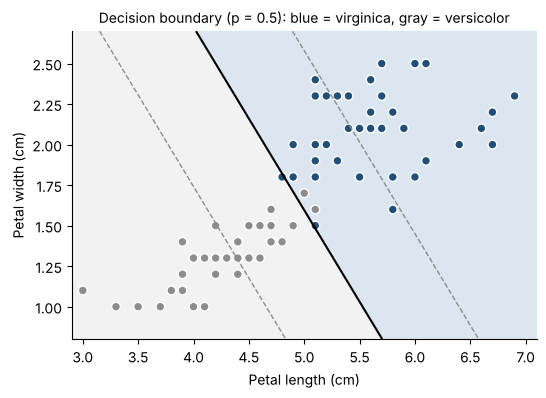

In [10]:
X2 = iris[["petal_length", "petal_width"]]
X2_train, X2_test, _, _ = train_test_split(X2, y, test_size=0.25, random_state=42, stratify=y)
model2 = LogisticRegression().fit(X2_train, y_train)
print("coef_     :", model2.coef_.round(2), "| columns:", list(X2.columns))
print("intercept_:", model2.intercept_.round(2))
print("test accuracy: 1 col =", round(model.score(X_test, y_test), 2), "| 2 cols =", round(model2.score(X2_test, y_test), 2))

def draw_boundary(m, data, labels, title):
    xx, yy = np.meshgrid(np.linspace(2.9, 7.1, 300), np.linspace(0.8, 2.7, 300))
    zone = m.predict_proba(pd.DataFrame({"petal_length": xx.ravel(), "petal_width": yy.ravel()}))[:, 1].reshape(xx.shape)
    plt.contourf(xx, yy, zone, levels=[0, 0.5, 1], colors=["#F2F2F2", "#DCE6F1"])
    plt.contour(xx, yy, zone, levels=[0.1, 0.9], colors=GRAY, linewidths=1, linestyles="--")
    plt.contour(xx, yy, zone, levels=[0.5], colors="black", linewidths=1.5)
    plt.scatter(data["petal_length"], data["petal_width"], c=np.where(labels == 1, BLUE, GRAY), edgecolor="white", s=40)
    plt.xlabel("Petal length (cm)"); plt.ylabel("Petal width (cm)"); plt.title(title, fontsize=10)

draw_boundary(model2, X2_train, y_train, "Decision boundary (p = 0.5): blue = virginica, gray = versicolor")
plt.show()

**Giải thích từng dòng**

- `X2 = iris[["petal_length", "petal_width"]]`: bảng **hai cột đề**: chiều dài và bề rộng cánh hoa.
- `model2.coef_.round(2)`: lần này `coef_` có hình (1, 2): mỗi cột đề một hệ số. Hệ số của cột nào lớn thì cột đó "có tiếng nói" lớn hơn (nếu hai cột cùng thang đo).
- `model.score(X_test, y_test)`: `score` của máy phân loại là **độ đúng nhãn** (accuracy) trên tập đưa vào, tiện hơn gọi `accuracy_score`.
- `def draw_boundary(m, data, labels, title):`: gói bước vẽ thành hàm vì sẽ dùng lại ở dưới: nhận mô hình, dữ liệu, nhãn và tiêu đề.
- `np.meshgrid(np.linspace(2.9, 7.1, 300), np.linspace(0.8, 2.7, 300))`: **mới:** tạo **lưới điểm phủ kín mặt phẳng**: 300 × 300 điểm, `xx` chứa hoành độ và `yy` chứa tung độ của từng điểm lưới. Ta sẽ hỏi mô hình đoán gì ở *mỗi* điểm lưới để tô màu vùng.
- `m.predict_proba(pd.DataFrame({...: xx.ravel(), ...: yy.ravel()}))[:, 1].reshape(xx.shape)`: `.ravel()` duỗi lưới 300×300 thành một cột dài 90.000 dòng để đưa vào mô hình; lấy xác suất virginica; rồi `.reshape(xx.shape)` xếp lại thành lưới 300×300 để tô màu.
- `plt.contourf(xx, yy, zone, levels=[0, 0.5, 1], colors=[...])`: **mới:** `contourf` tô màu các **vùng** theo giá trị `zone`; với `levels=[0, 0.5, 1]` ta có hai vùng: xác suất dưới 0,5 (xám nhạt, máy đoán versicolor) và trên 0,5 (xanh nhạt, máy đoán virginica).
- `plt.contour(xx, yy, zone, levels=[0.5], ...)`: `contour` (không có f) chỉ **vẽ đường** nơi `zone = 0,5`: chính là đường biên quyết định.
- `plt.contour(xx, yy, zone, levels=[0.1, 0.9], ..., linestyles="--")`: thêm hai đường **đứt** ở mức 10% và 90%: khoảng giữa hai đường là **vùng mờ** nơi máy chưa chắc.
- `c=np.where(labels == 1, BLUE, GRAY)`: `np.where(điều kiện, a, b)` chọn `a` nếu đúng, `b` nếu sai, cho từng cây: virginica tô xanh, versicolor tô xám.

**Cách đọc**

- **Con số:** hai hệ số là **2,52** (chiều dài) và **2,23** (bề rộng), cùng dương: cánh càng dài, càng rộng thì càng nghiêng về virginica. Độ đúng trên tập thi: một cột **88%**, hai cột **92%** (2 cây sai thay vì 3, trên 25 cây).
- **Bức tranh:** hai vùng tô màu (xanh nhạt: máy đoán virginica; xám nhạt: máy đoán versicolor) **tách nhau bởi một đường thẳng nghiêng** (đường đen, xác suất 50%). Hai đường đứt xám là mức 10% và 90%: khoảng giữa chúng là *vùng mờ* nơi máy chưa chắc. Đám điểm xanh (virginica) nằm phía trên bên phải, đám xám phía dưới bên trái, chỉ vài điểm lấn qua đường.
- **Ý nghĩa:** hồi quy logistic **luôn cho đường biên thẳng** (với ba cột là mặt phẳng, với nhiều cột là "siêu phẳng"). Đó vừa là sức mạnh (đơn giản, ổn định, đọc được) vừa là giới hạn (chặng 6).
- **Cẩn thận về cỡ mẫu:** chênh một cây trên 25 cây là **chưa đủ** để nói hai cột tốt hơn một cột. Điều ta thật sự nhìn ra từ hình là *hai cột cùng chỉ về một hướng*.

Cuối cùng là **núm vặn `C`**. `LogisticRegression` mặc định có một khoản phạt kiểu Ridge (B6) lên các hệ số, và `C` là **nghịch đảo độ chặt**: `C` **nhỏ** thì dây cương **chặt** (hệ số bị kìm nhỏ), `C` **lớn** thì dây **lỏng**. (Ngược chiều với `alpha` ở B6, hãy nhớ kỹ!)

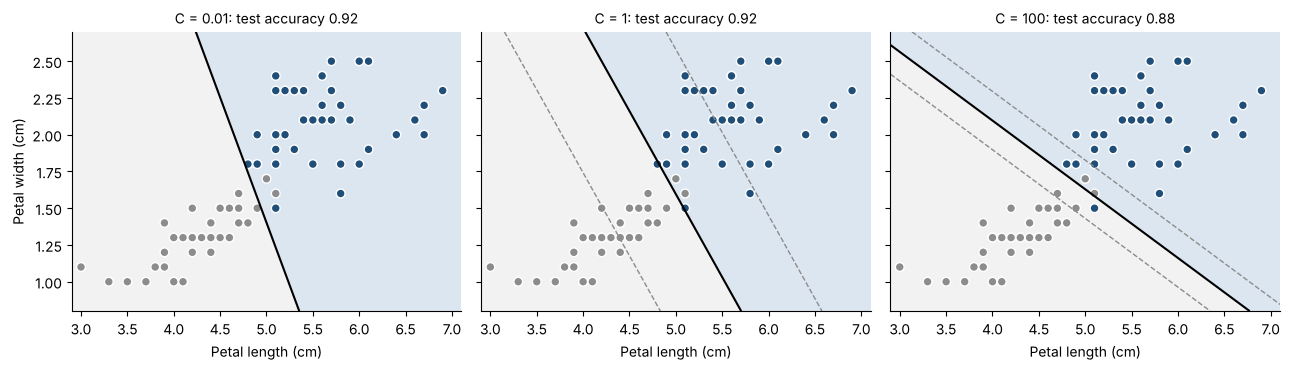

{0.01: [0.22, 0.13], 1: [2.52, 2.23], 100: [5.18, 11.08]}


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, C in zip(axes, [0.01, 1, 100]):
    m = LogisticRegression(C=C, max_iter=1000).fit(X2_train, y_train)
    plt.sca(ax)
    draw_boundary(m, X2_train, y_train, f"C = {C}: test accuracy {m.score(X2_test, y_test):.2f}")
    ax.set_ylabel("Petal width (cm)" if C == 0.01 else "")
plt.tight_layout(); plt.show()
print({C: LogisticRegression(C=C, max_iter=1000).fit(X2_train, y_train).coef_.round(2).tolist()[0] for C in [0.01, 1, 100]})

**Giải thích từng dòng**

- `fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)`: (đã học `subplots`) ba khung cạnh nhau, dùng chung trục dọc.
- `for ax, C in zip(axes, [0.01, 1, 100]):`: (đã học `zip`) mỗi khung ứng một giá trị `C`: rất chặt, mặc định, rất lỏng.
- `LogisticRegression(C=C, max_iter=1000)`: **mới:** núm `C`. Mặc định `C = 1`.
- `plt.sca(ax)`: `sca` = *set current axes*: bảo `plt` rằng từ giờ vẽ vào khung `ax`, để hàm `draw_boundary` (dùng `plt.contourf`...) vẽ đúng chỗ.
- `print({C: ...coef_.round(2).tolist()[0] for C in [...]})`: in hệ số của ba mô hình: `.tolist()[0]` đổi mảng một dòng thành danh sách hai số.

**Cách đọc**

- **Con số:** `C = 0,01` cho hệ số khoảng **0,22** và **0,13** (rất nhỏ), `C = 1` cho 2,52 và 2,23, `C = 100` cho hệ số lớn hơn nhiều.
- **Bức tranh:** ở `C = 0,01` hai đường đứt (10% và 90%) **cách xa nhau** đến mức văng ra ngoài khung hình: vùng mờ bao trùm cả đám điểm, máy rất dè dặt. Ở `C = 100` hai đường đứt **ép sát** đường đen: chữ S dựng đứng, máy chắc nịch; đồng thời đường đen **đổi hướng** (thoải hơn) vì máy cố ôm sát vài cây lấn ranh. Độ đúng tập thi 0,92; 0,92 và 0,88 (nhớ rằng mỗi cây sai là 4 điểm phần trăm).
- **Ý nghĩa:** `C` là siêu tham số (B6): máy không tự biết nên kìm chặt đến đâu. Cùng bài học: không chọn `C` bằng tập thi mà bằng kiểm định chéo trên tập học (sẽ có `LogisticRegressionCV`, `GridSearchCV` ở phần D).
- **Nhắc lại từ B6:** vì có khoản phạt, **nên chuẩn hóa cột** khi dùng nhiều cột khác thang đo (ở đây hai cột cùng đơn vị cm nên tạm bỏ qua).

**Mang về chặng 5:** nhiều cột thì `coef_` có một số cho mỗi cột; đường biên quyết định là **đường thẳng** (mặt phẳng...). `C` nhỏ là kìm chặt, `C` lớn là thả lỏng (ngược với `alpha`).

## Chặng 6: Kiểm định và giới hạn, khi ranh giới không phải đường thẳng

**Câu hỏi:** mô hình logistic này hơn máy lười bao nhiêu, và có bài nào nó bó tay không?

Trước hết so với mốc lười và đo bằng nhiều lần chia sổ (thói quen từ A4), rồi thử một bài mà ranh giới **cong**.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
for name, m, data in [("lazy (most frequent)", DummyClassifier(strategy="most_frequent"), X2),
                      ("logistic, 1 column", LogisticRegression(), X),
                      ("logistic, 2 columns", LogisticRegression(), X2)]:
    scores = cross_val_score(m, data, y, cv=cv)
    print(f"{name:22s} mean accuracy = {scores.mean():.3f}   spread (std) = {scores.std():.3f}   ({len(scores)} scores)")

lazy (most frequent)   mean accuracy = 0.500   spread (std) = 0.000   (50 scores)


logistic, 1 column     mean accuracy = 0.940   spread (std) = 0.042   (50 scores)


logistic, 2 columns    mean accuracy = 0.948   spread (std) = 0.051   (50 scores)


**Giải thích từng dòng**

- `from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold`: (đã học `cross_val_score` và `RepeatedKFold` ở B6) `RepeatedStratifiedKFold` là bản **giữ tỉ lệ nhóm** cho bài phân loại.
- `cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)`: chia 100 cây thành 5 phần, lấy lần lượt một phần làm tập thi; lặp 10 lần với các cách chia khác nhau: **50 điểm số** thay vì một.
- `for name, m, data in [(...), (...), (...)]:`: lặp qua ba ứng viên, mỗi ứng viên là một bộ ba (tên, mô hình, bảng đề). Cú pháp `for a, b, c in danh_sách_bộ_ba` đã học.
- `cross_val_score(m, data, y, cv=cv)`: (đã học) với bài phân loại, điểm mặc định là **độ đúng nhãn**.
- `f"{name:22s} ..."`: trong f-string, `:22s` dành đúng 22 ký tự cho chuỗi để các dòng thẳng cột.

**Cách đọc:** máy lười (luôn đoán một loài) đạt **0,50**: đúng bằng tỉ lệ ngẫu nhiên khi hai loài cân bằng. Logistic một cột đạt khoảng **0,94**, hai cột khoảng **0,95**: tốt hơn mốc lười rất rõ, và hai cột chỉ hơn một cột chút xíu (chênh nhỏ hơn mức dao động giữa các lần chia, như bài học A4). Với chị Mai, **một cây thước đo bề rộng cánh là đã đủ để đoán đúng khoảng 94 cây trên 100**.

Giờ là bài mà đường thẳng bó tay. Dữ liệu **tự sinh** (không phải dữ liệu thật) để minh họa: hai nhóm điểm xếp thành **hai vòng tròn đồng tâm**.

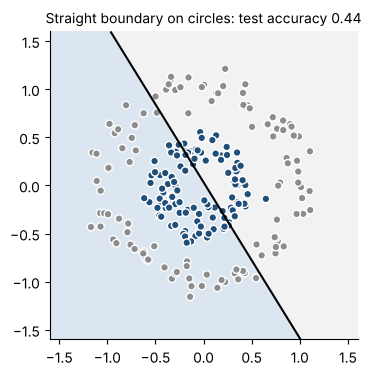

In [13]:
from sklearn.datasets import make_circles
Xc, yc = make_circles(n_samples=300, noise=0.1, factor=0.4, random_state=0)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, random_state=42, stratify=yc)
circ = LogisticRegression().fit(Xc_train, yc_train)
xx, yy = np.meshgrid(np.linspace(-1.6, 1.6, 300), np.linspace(-1.6, 1.6, 300))
zone = circ.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
plt.contourf(xx, yy, zone, levels=[0, 0.5, 1], colors=["#F2F2F2", "#DCE6F1"])
plt.contour(xx, yy, zone, levels=[0.5], colors="black", linewidths=1.5)
plt.scatter(Xc_train[:, 0], Xc_train[:, 1], c=np.where(yc_train == 1, BLUE, GRAY), edgecolor="white", s=30)
plt.title(f"Straight boundary on circles: test accuracy {circ.score(Xc_test, yc_test):.2f}", fontsize=10)
plt.gca().set_aspect("equal"); plt.show()

**Giải thích từng dòng**

- `from sklearn.datasets import make_circles`: **mới:** `make_circles` **tự sinh** dữ liệu hai vòng tròn đồng tâm: nhóm 0 ở vòng ngoài, nhóm 1 ở vòng trong. Dữ liệu tự sinh dùng để *dựng tình huống thí nghiệm*, không phải dữ liệu thật.
- `make_circles(n_samples=300, noise=0.1, factor=0.4, random_state=0)`: 300 điểm; `noise` là độ nhòe; `factor=0.4` là tỉ lệ bán kính vòng trong so với vòng ngoài; `random_state` là hạt giống. Trả về `Xc` (bảng hai cột tọa độ, dạng mảng numpy) và `yc` (nhãn).
- `np.c_[xx.ravel(), yy.ravel()]`: `np.c_[a, b]` ghép hai cột dài cạnh nhau thành bảng hai cột (cách gọn thay cho `pd.DataFrame`). Đưa thẳng cho mô hình vì ở đây `Xc` là mảng numpy, không có tên cột.
- `plt.gca().set_aspect("equal")`: `gca` = *get current axes*; `set_aspect("equal")` bắt hai trục cùng tỉ lệ để vòng tròn trông tròn.

**Cách đọc**

- **Con số:** độ đúng chỉ khoảng **44%**, ngang tung đồng xu (hai nhóm cân bằng).
- **Bức tranh:** nhóm xanh nằm trong lòng nhóm xám như hạt trong vỏ. **Không có đường thẳng nào** tách được "hạt" khỏi "vỏ": bất kể đặt đường ở đâu, mỗi bên đều lẫn cả hai màu. Máy vẽ một đường gần như tùy ý, và xác suất ở mọi nơi quanh 0,5.
- **Ý nghĩa:** hồi quy logistic đoán tốt khi hai nhóm **tách được bằng ranh giới phẳng**; khi ranh giới cong, ta cần mô hình khác (hoặc *tạo thêm cột* như `PolynomialFeatures` ở B5). Các buổi sau là những mô hình cho ranh giới cong: **k-NN (C3), cây quyết định (C5), SVM (C6)**.

## Phán quyết và bài học nghề

**Phán quyết cho chị Mai.** Chỉ cần đo **bề rộng cánh hoa**: mô hình logistic một cột đoán đúng khoảng 94 cây trên 100, và nói được mức chắc chắn (ví dụ "cây cánh rộng 1,9 cm: khoảng 70% là virginica"). Với cây rơi vào đoạn **từ khoảng 1,5 đến 1,9 cm** (vùng dốc), nên đo thêm chiều dài hoặc kiểm tra tay thay vì tin ngay.

**Bài học nghề.**

1. **Hồi quy logistic = đường thẳng + sigmoid**, cho ra xác suất. Cái tên có chữ "hồi quy" nhưng việc là *phân loại*.
2. **`coef_` là log-odds mỗi đơn vị**; `exp(coef_)` là tỉ số odds; điểm 50/50 là `−intercept_ / coef_`.
3. **Chấm bằng log-loss**: phạt nặng tự tin mà sai; mốc đáy cho hai nhóm cân bằng là 0,693.
4. **Đường biên quyết định là đường thẳng**; `C` nhỏ là kìm chặt (ngược với `alpha`).
5. **Đo bằng nhiều lần chia** và so với **máy lười**; đừng tin chênh một hai ca trên tập thi nhỏ.
6. **Giới hạn:** ranh giới cong thì logistic bó tay: cần cột mới hoặc mô hình khác.

**Một điều thành thật:** mọi phát biểu "mỗi cm tăng thì odds nhân bấy nhiêu" chỉ đúng **trong phạm vi dữ liệu đã thấy** (bề rộng khoảng từ 1 đến 2,5 cm); ngoài phạm vi đó là đoán mò, giống lời cảnh báo ngoại suy ở B1.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Đường thẳng đoán nhóm cho kết quả ngoài khoảng 0 đến 1: vô nghĩa như xác suất. |
| 2 | Hồi quy logistic = đường thẳng `z` + sigmoid `p = 1 / (1 + e^(−z))`; cần `X` toàn số, không `NaN`; `y` là nhãn. |
| 3 | `coef_` là log-odds mỗi đơn vị; `exp(coef_)` là tỉ số odds; điểm 50/50 là `−intercept_ / coef_`. |
| 4 | `fit` giảm log-loss, phạt nặng tự tin mà sai; log-loss mốc đáy là 0,693 với hai nhóm cân bằng. |
| 5 | Nhiều cột: đường biên là đường thẳng; `C` nhỏ kìm chặt, `C` lớn thả lỏng. |
| 6 | Đo bằng kiểm định chéo lặp so với máy lười; ranh giới cong làm logistic bó tay. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Khả năng thuộc một nhóm | xác suất (probability) | `predict_proba` |
| Hình chữ S ép về 0 đến 1 | hàm sigmoid | `1 / (1 + np.exp(-z))` |
| Tỉ lệ cược "bao nhiêu lần có ứng với một lần không" | odds | `p / (1 - p)` |
| Điểm của đường thẳng trước khi ép | log-odds | `z = intercept_ + coef_ * x` |
| Mỗi đơn vị `x` thì odds nhân bao nhiêu | tỉ số odds (odds ratio) | `np.exp(model.coef_)` |
| Mức phạt khi tự tin mà sai | log-loss (cross-entropy) | `log_loss(y, proba)` |
| Đường phân hai vùng đoán | đường biên quyết định | `contour(..., levels=[0.5])` |
| Núm vặn độ kìm hệ số (ngược `alpha`) | nghịch đảo độ chặt | `C=` |
| Máy luôn đoán nhóm phổ biến | mốc cơ sở (baseline) | `DummyClassifier` |

**Thử thách tự làm**

1. Ở chặng 3, đổi cây giả định thành bề rộng 1,2 cm rồi 2,3 cm. Tính xác suất bằng tay và bằng `predict_proba`. Ở bề rộng nào máy chắc nhất?
2. Ở chặng 6, thêm `PolynomialFeatures(degree=2)` (như B5) vào trước `LogisticRegression` cho dữ liệu hai vòng tròn, bằng `make_pipeline`. Độ đúng tăng lên bao nhiêu? Vì sao?
3. Kể chuyện với dữ liệu khác: dùng `load_wine(as_frame=True)`, giữ hai loại rượu đầu (nhãn 0 và 1) và một cột đề tùy chọn (ví dụ `alcohol`). Đọc `coef_`, tỉ số odds mỗi 1 độ cồn, và điểm 50/50.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích vì sao không dùng đường thẳng thường để đoán nhóm.
- [ ] Mô tả hai bước của hồi quy logistic: đường thẳng rồi sigmoid.
- [ ] Đọc được `coef_` thành tỉ số odds và tìm được điểm 50/50.
- [ ] Giải thích log-loss phạt thế nào và vì sao đúng nhãn chưa đủ.
- [ ] Hiểu `C` và vì sao nó ngược chiều `alpha`.
- [ ] Nêu giới hạn: ranh giới cong thì logistic bó tay.

## Phần thưởng (Tip pro): `decision_function` và vì sao `predict` không dùng ngưỡng 0,5 "cứng"


Ngoài `predict` và `predict_proba`, máy logistic còn có `decision_function(X)`: trả về chính **`z` (log-odds)** trước khi qua sigmoid. `predict` chỉ nhìn **dấu của `z`**: dương thì đoán nhóm `1`, âm thì nhóm `0`, tương đương ngưỡng 0,5 trên xác suất. Muốn đổi ngưỡng (ví dụ "chỉ gọi là virginica khi chắc trên 80%") ta không có tham số trong `predict`; phải tự cắt `predict_proba(X)[:, 1] > 0.8`, như đã làm ở A6. Buổi C2 sẽ nói vì sao việc đổi ngưỡng quan trọng.

In [14]:
z_test = model.decision_function(X_test)
p_test = model.predict_proba(X_test)[:, 1]
print("decision_function (first 5):", z_test[:5].round(2))
print("sigmoid(z)                 :", (1 / (1 + np.exp(-z_test[:5]))).round(3))
print("predict_proba[:, 1]        :", p_test[:5].round(3))
print("predict follows sign of z  :", bool(((z_test > 0).astype(int) == model.predict(X_test)).all()))

decision_function (first 5): [ 2.45  1.26  0.08 -0.32  0.47]
sigmoid(z)                 : [0.92  0.779 0.52  0.422 0.616]
predict_proba[:, 1]        : [0.92  0.779 0.52  0.422 0.616]
predict follows sign of z  : True


**Giải thích từng dòng**

- `model.decision_function(X_test)`: trả về `z` (log-odds) cho từng cây thi.
- `(1 / (1 + np.exp(-z_test[:5]))).round(3)`: tự ép `z` qua sigmoid: phải ra đúng bằng `predict_proba`.
- `((z_test > 0).astype(int) == model.predict(X_test)).all()`: kiểm tra: đổi `z > 0` thành 1/0 rồi so với `predict`; `.all()` hỏi "tất cả đều Đúng?".